Lab2 Peng CHEN 22409126

In [2]:
!pip install -q transformers datasets huggingface_hub scipy scikit-learn pandas matplotlib

In [3]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [4]:
import os
CACHE_DIR = "/content/drive/MyDrive/M2-pariscite/labs_mt/lab2/cache"
os.makedirs(CACHE_DIR, exist_ok=True)
print("Cache directory:", CACHE_DIR)

Cache directory: /content/drive/MyDrive/M2-pariscite/labs_mt/lab2/cache


In [5]:
import os
import numpy as np
import pandas as pd
import torch

from transformers import AutoTokenizer, AutoModelForMaskedLM
from datasets import load_dataset

In [6]:
from huggingface_hub import login
login()

**To get the dataset:**

In [7]:
MODEL_ID = "google-bert/bert-base-multilingual-cased"
REVISION = "3f076fdb1ab68d5b2880cb87a0886f315b8146f8"  # pin the exact checkpoint

tok = AutoTokenizer.from_pretrained(MODEL_ID, revision=REVISION)
model = AutoModelForMaskedLM.from_pretrained(MODEL_ID, revision=REVISION).eval()
torch.set_grad_enabled(False)  # inference only: saves memory and time

print(len(tok))  # should match config.vocab_size
print(model.bert.encoder.layer[0])  # attention, intermediate, output

config.json:   0%|          | 0.00/625 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/996k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.96M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  714MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

[transformers] BertForMaskedLM LOAD REPORT from: google-bert/bert-base-multilingual-cased
Key                         | Status     |  | 
----------------------------+------------+--+-
bert.pooler.dense.bias      | UNEXPECTED |  | 
bert.pooler.dense.weight    | UNEXPECTED |  | 
cls.seq_relationship.weight | UNEXPECTED |  | 
cls.seq_relationship.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


119547
BertLayer(
  (attention): BertAttention(
    (self): BertSelfAttention(
      (query): Linear(in_features=768, out_features=768, bias=True)
      (key): Linear(in_features=768, out_features=768, bias=True)
      (value): Linear(in_features=768, out_features=768, bias=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (output): BertSelfOutput(
      (dense): Linear(in_features=768, out_features=768, bias=True)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
  )
  (intermediate): BertIntermediate(
    (dense): Linear(in_features=768, out_features=3072, bias=True)
    (intermediate_act_fn): GELUActivation()
  )
  (output): BertOutput(
    (dense): Linear(in_features=3072, out_features=768, bias=True)
    (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
    (dropout): Dropout(p=0.1, inplace=False)
  )
)


In [8]:
def load_flores(code, split):
    """One FLORES+ language variety as a DataFrame sorted by sentence id."""
    df = load_dataset("openlanguagedata/flores_plus", code, split=split).to_pandas()
    df["id"] = df["id"].astype(int)
    return df.sort_values("id").reset_index(drop=True)

# the six languages of Parts 2 and 3; add the codes of Table 2 for Part 1
LANGS = ["eng_Latn", "fra_Latn", "deu_Latn", "rus_Cyrl", "cmn_Hans", "yor_Latn"]
LANGS = ["eng_Latn", "fra_Latn", "deu_Latn", "rus_Cyrl", "cmn_Hans", "yor_Latn"]
dev = {code: load_flores(code, "dev") for code in LANGS}
assert all((d["id"] == dev["eng_Latn"]["id"]).all() for d in dev.values())

README.md:   0%|          | 0.00/73.7k [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/228 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/222 [00:00<?, ?it/s]

eng_Latn.jsonl:   0%|          | 0.00/423k [00:00<?, ?B/s]

eng_Latn.jsonl:   0%|          | 0.00/440k [00:00<?, ?B/s]

...

Resolving data files:   0%|          | 0/222 [00:00<?, ?it/s]

yor_Latn.jsonl:   0%|          | 0.00/459k [00:00<?, ?B/s]

yor_Latn.jsonl:   0%|          | 0.00/477k [00:00<?, ?B/s]

Generating dev split:   0%|          | 0/997 [00:00<?, ? examples/s]

Generating devtest split:   0%|          | 0/1012 [00:00<?, ? examples/s]

In [9]:
devtest = {code: load_flores(code, "devtest") for code in LANGS}
assert all((d["id"] == devtest["eng_Latn"]["id"]).all() for d in devtest.values())

Resolving data files:   0%|          | 0/228 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/222 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/228 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/222 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/228 [00:00<?, ?it/s]

...

Resolving data files:   0%|          | 0/222 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/228 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/222 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/228 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/222 [00:00<?, ?it/s]

In [10]:
def encode(sentences, max_length=256):
  enc = tok(sentences, padding=True, truncation=True, max_length=max_length,
        return_tensors="pt", return_special_tokens_mask=True)
  special = enc.pop("special_tokens_mask").bool()
  keep = enc["attention_mask"].bool() & ~special # (B, T): real word pieces
  return enc, keep

In [11]:
def sentence_reps(sentences, batch_size=32):
  """Mean-pooled hidden states of all layers: array of shape (13, N, 768)."""
  chunks = []
  for i in range(0, len(sentences), batch_size):
      enc, keep = encode(sentences[i:i + batch_size])
      hs = model.bert(**enc, output_hidden_states=True).hidden_states
      H = torch.stack(hs) # (13, B, T, 768)
      w = keep.unsqueeze(-1).float() # (B, T, 1)
      chunks.append((H * w).sum(2) / w.sum(1)) # (13, B, 768)
  return torch.cat(chunks, dim=1).numpy()

In [12]:
print(dev["eng_Latn"].columns)
print(devtest["eng_Latn"].columns)
print()
dev["eng_Latn"].head(1)

Index(['id', 'iso_639_3', 'iso_15924', 'glottocode', 'variant', 'text', 'url',
       'domain', 'topic', 'has_image', 'has_hyperlink', 'last_updated',
       'split'],
      dtype='object')
Index(['id', 'iso_639_3', 'iso_15924', 'glottocode', 'variant', 'text', 'url',
       'domain', 'topic', 'has_image', 'has_hyperlink', 'last_updated',
       'split'],
      dtype='object')



,id,iso_639_3,iso_15924,glottocode,variant,text,url,domain,topic,has_image,has_hyperlink,last_updated,split
0,0,eng,Latn,stan1293,,"On Monday, scientists from the Stanford Univer...",https://en.wikinews.org/wiki/Scientists_say_ne...,wikinews,health,yes,yes,1.0,dev


In [13]:
# part2 exo14
test_reps = sentence_reps(dev["eng_Latn"]["text"].tolist()[:5])
print(test_reps.shape)

(13, 5, 768)


In [14]:
import os, numpy as np
CACHE_DIR = "/content/drive/MyDrive/M2-pariscite/labs_mt/lab2/cache"
os.makedirs(CACHE_DIR, exist_ok=True)

In [15]:
for lang in LANGS:
    dev_path = os.path.join(CACHE_DIR, f"{lang}_dev.npy")
    devtest_path = os.path.join(CACHE_DIR, f"{lang}_devtest.npy")

    if os.path.exists(dev_path) and os.path.exists(devtest_path):
        representations_dev = np.load(dev_path)
        representations_devtest = np.load(devtest_path)
        print(lang, representations_dev.shape, representations_devtest.shape)
        continue

    representations_dev = sentence_reps(dev[lang]["text"].tolist())
    np.save(dev_path, representations_dev)

    representations_devtest = sentence_reps(devtest[lang]["text"].tolist())
    np.save(devtest_path, representations_devtest)

    print(lang, representations_dev.shape, representations_devtest.shape)

eng_Latn (13, 997, 768) (13, 1012, 768)
fra_Latn (13, 997, 768) (13, 1012, 768)
deu_Latn (13, 997, 768) (13, 1012, 768)
rus_Cyrl (13, 997, 768) (13, 1012, 768)
cmn_Hans (13, 997, 768) (13, 1012, 768)
yor_Latn (13, 997, 768) (13, 1012, 768)


In [16]:
import matplotlib.pyplot as plt

In [17]:
#exo15
def compute_average_norm(vectors: np.ndarray) -> float:

  """Compute the average L2 norm of a set of sentence vectors."""
  norms = np.linalg.norm(vectors, axis=1)
  return norms.mean()


def compute_average_cosine(vectors: np.ndarray, number_of_pairs: int = 1000, seed: int = 42) -> float:
  """Compute the average cosine similarity of random pairs of distinct sentence vectors."""
  random_generator = np.random.default_rng(seed)
  number_of_sentences = len(vectors)

  first_indices = random_generator.integers(0, number_of_sentences, number_of_pairs)
  second_indices = random_generator.integers(0, number_of_sentences, number_of_pairs)

  # Make sure the two sentences in each pair are different
  same_indices = first_indices == second_indices
  while same_indices.any():
    second_indices[same_indices] = random_generator.integers(0, number_of_sentences, same_indices.sum())
    same_indices = first_indices == second_indices

  first_vectors = vectors[first_indices]
  second_vectors = vectors[second_indices]

  cosine_similarities = np.sum(first_vectors * second_vectors, axis=1) / (
        np.linalg.norm(first_vectors, axis=1) * np.linalg.norm(second_vectors, axis=1))
  return cosine_similarities.mean()

average_norms = {}
average_cosines = {}

for lang in LANGS:
  representations_dev = np.load(os.path.join(CACHE_DIR, f"{lang}_dev.npy"))

  average_norms[lang] = []
  average_cosines[lang] = []

  for layer in range(13):
      layer_vectors = representations_dev[layer]

      average_norms[lang].append(compute_average_norm(layer_vectors))
      average_cosines[lang].append(compute_average_cosine(layer_vectors))

In [18]:
average_norms = {}
average_cosines = {}

for lang in LANGS:
    representations_dev = np.load(os.path.join(CACHE_DIR, f"{lang}_dev.npy"))

    average_norms[lang] = []
    average_cosines[lang] = []

    for layer in range(13):
        layer_vectors = representations_dev[layer]

        average_norms[lang].append(compute_average_norm(layer_vectors))
        average_cosines[lang].append(compute_average_cosine(layer_vectors))

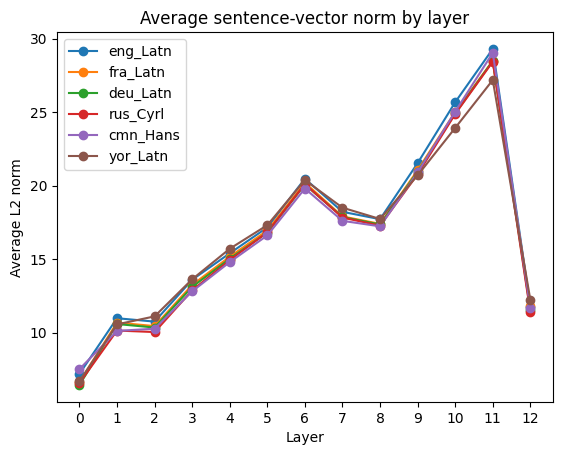

In [19]:
layers = range(13)
for lang in LANGS:
    plt.plot(layers, average_norms[lang], marker="o", label=lang)
plt.xlabel("Layer")
plt.ylabel("Average L2 norm")
plt.title("Average sentence-vector norm by layer")
plt.xticks(layers)
plt.legend()
plt.show()

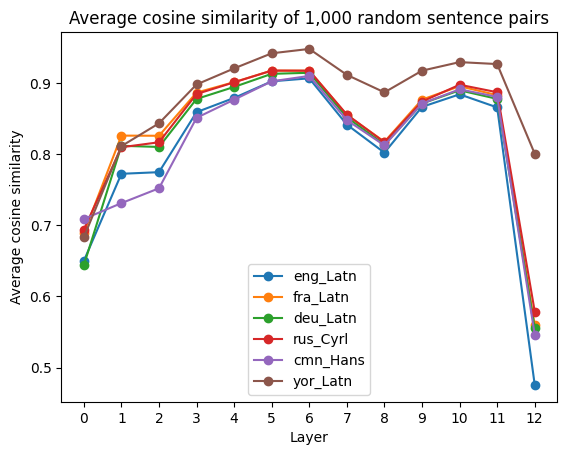

In [20]:
for lang in LANGS:
    plt.plot(layers, average_cosines[lang], marker="o", label=lang)

plt.xlabel("Layer")
plt.ylabel("Average cosine similarity")
plt.title("Average cosine similarity of 1,000 random sentence pairs")
plt.xticks(layers)
plt.legend()
plt.show()

In [21]:
q15_results = []

for lang in LANGS:
    representations_dev = np.load(os.path.join(CACHE_DIR, f"{lang}_dev.npy"))

    for layer in range(13):
        layer_vectors = representations_dev[layer]

        average_norm = compute_average_norm(layer_vectors)
        average_cosine = compute_average_cosine(layer_vectors)

        q15_results.append({
            "language": lang,
            "layer": layer,
            "average_norm": average_norm,
            "average_cosine": average_cosine
        })

q15_dataframe = pd.DataFrame(q15_results)

display(q15_dataframe)

,language,layer,average_norm,average_cosine
0,eng_Latn,0,7.204269,0.649957
1,eng_Latn,1,10.984295,0.772401
2,eng_Latn,2,10.754804,0.774683
3,eng_Latn,3,13.601475,0.859069
4,eng_Latn,4,15.399758,0.879041
...,...,...,...,...
73,yor_Latn,8,17.732824,0.886849
74,yor_Latn,9,20.703341,0.917335
75,yor_Latn,10,23.927204,0.929353
76,yor_Latn,11,27.185053,0.926632


In [22]:
#exo19
for lang in LANGS:
    print(lang, np.round(average_cosines[lang], 3))

eng_Latn [0.65  0.772 0.775 0.859 0.879 0.902 0.907 0.842 0.802 0.866 0.884 0.866
 0.476]
fra_Latn [0.689 0.826 0.826 0.887 0.901 0.917 0.917 0.855 0.817 0.877 0.895 0.883
 0.56 ]
deu_Latn [0.644 0.812 0.81  0.878 0.894 0.913 0.914 0.852 0.813 0.871 0.89  0.878
 0.556]
rus_Cyrl [0.694 0.81  0.817 0.885 0.901 0.917 0.917 0.856 0.817 0.874 0.898 0.887
 0.579]
cmn_Hans [0.709 0.731 0.752 0.851 0.877 0.902 0.91  0.848 0.812 0.871 0.891 0.881
 0.546]
yor_Latn [0.683 0.811 0.843 0.898 0.921 0.942 0.948 0.911 0.887 0.917 0.929 0.927
 0.801]


In [23]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

In [24]:
#27
# Load cached sentence representations
representations_dev = {lang: np.load(os.path.join(CACHE_DIR, f"{lang}_dev.npy")) for lang in LANGS}
representations_devtest = {lang: np.load(os.path.join(CACHE_DIR, f"{lang}_devtest.npy")) for lang in LANGS}

language_classification_accuracies = []

# Train and evaluate one classifier for each layer
for layer in range(13):
  # Combine the six languages into one training set
  training_representations = np.concatenate([representations_dev[lang][layer] for lang in LANGS])
  training_languages = np.concatenate([[lang] * len(representations_dev[lang][layer]) for lang in LANGS])
  # Combine the six languages into one evaluation set
  evaluation_representations = np.concatenate([representations_devtest[lang][layer] for lang in LANGS])
  evaluation_languages = np.concatenate([[lang] * len(representations_devtest[lang][layer]) for lang in LANGS])
  # Standardise the vectors, then train logistic regression
  classifier = Pipeline([
      ("scaler", StandardScaler()),
      ("logistic_regression", LogisticRegression(max_iter=2000))
  ])
   # Fit on dev and predict on devtest sentences
  classifier.fit(training_representations, training_languages)
  predicted_languages = classifier.predict(evaluation_representations)

  accuracy = accuracy_score(evaluation_languages, predicted_languages)
  language_classification_accuracies.append(accuracy)

  print(f"Layer {layer}: {accuracy}")

Layer 0: 1.0
Layer 1: 0.9998353096179183
Layer 2: 1.0
Layer 3: 1.0
Layer 4: 1.0
Layer 5: 1.0
Layer 6: 1.0
Layer 7: 1.0
Layer 8: 0.9998353096179183
Layer 9: 1.0
Layer 10: 1.0
Layer 11: 0.9998353096179183
Layer 12: 0.9998353096179183


In [25]:
#28
centred_language_classification_accuracies = []

for layer in range(13):
  centred_training_representations = []
  centred_evaluation_representations = []
  training_languages = []
  evaluation_languages = []

  # Centre each language separately using the mean estimated on dev
  for lang in LANGS:
      language_mean = representations_dev[lang][layer].mean(axis=0)

      centred_training_representations.append(representations_dev[lang][layer] - language_mean)
      centred_evaluation_representations.append(representations_devtest[lang][layer] - language_mean)

      training_languages.extend([lang] * len(representations_dev[lang][layer]))
      evaluation_languages.extend([lang] * len(representations_devtest[lang][layer]))

  # Combine the six languages
  centred_training_representations = np.concatenate(centred_training_representations)
  centred_evaluation_representations = np.concatenate(centred_evaluation_representations)

  # Same classifier as Exercise 27
  classifier = Pipeline([
      ("scaler", StandardScaler()),
      ("logistic_regression", LogisticRegression(max_iter=2000))
  ])

  classifier.fit(centred_training_representations, training_languages)
  predicted_languages = classifier.predict(centred_evaluation_representations)

  accuracy = accuracy_score(evaluation_languages, predicted_languages)
  centred_language_classification_accuracies.append(accuracy)

  print(f"Layer {layer}: {accuracy}")

Layer 0: 0.16666666666666666
Layer 1: 0.16666666666666666
Layer 2: 0.16666666666666666
Layer 3: 0.16666666666666666
Layer 4: 0.16666666666666666
Layer 5: 0.16666666666666666
Layer 6: 0.16666666666666666
Layer 7: 0.16666666666666666
Layer 8: 0.16666666666666666
Layer 9: 0.16666666666666666
Layer 10: 0.16666666666666666
Layer 11: 0.16666666666666666
Layer 12: 0.16666666666666666


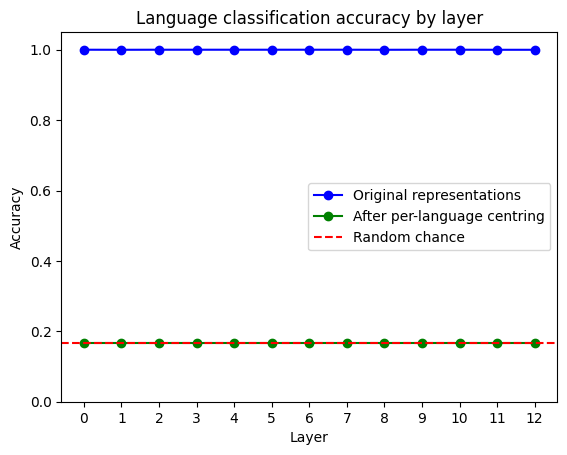

In [26]:
#29
layers = range(13)
random_chance = 1 / len(LANGS)

# Plot original and centred classification accuracies
plt.plot(layers, language_classification_accuracies, marker="o", color="blue", label="Original representations")
plt.plot(layers, centred_language_classification_accuracies, marker="o", color="green", label="After per-language centring")
plt.axhline(random_chance, linestyle="--", color="red", label="Random chance")

plt.xlabel("Layer")
plt.ylabel("Accuracy")
plt.title("Language classification accuracy by layer")
plt.xticks(layers)
plt.ylim(0, 1.05)
plt.legend()
plt.show()

In [27]:
#task 2.4
#exo 33-37
def compute_precision_at_1(source_vectors: np.ndarray, target_vectors: np.ndarray) -> float:
    """Compute Precision at 1 for parallel sentence retrieval using cosine similarity."""

    # Normalise each sentence vector to unit length
    source_normalised = source_vectors / np.linalg.norm(source_vectors, axis=1, keepdims=True)
    target_normalised = target_vectors / np.linalg.norm(target_vectors, axis=1, keepdims=True)

    cosine_similarities = source_normalised @ target_normalised.T
    nearest_neighbour_indices = np.argmax(cosine_similarities, axis=1)
    # Parallel sentences have the same index in devtest
    correct_translation_indices = np.arange(len(source_vectors))

    # Proportion whose top-1 neighbour is the true translation
    return np.mean(nearest_neighbour_indices == correct_translation_indices)

In [28]:
english = "eng_Latn"
target_languages = [lang for lang in LANGS if lang != english]

raw_retrieval_precision_at_1 = {lang: [] for lang in target_languages}
centred_retrieval_precision_at_1 = {lang: [] for lang in target_languages}

for layer in range(13):
    # English representations at this layer
    english_dev = representations_dev[english][layer]
    english_devtest = representations_devtest[english][layer]
    # Estimate the English mean on dev
    english_mean = english_dev.mean(axis=0)
    # Centre English devtest representations using the dev mean
    english_devtest_centred = english_devtest - english_mean

    for lang in target_languages:
        # Target-language representations at this layer
        target_dev = representations_dev[lang][layer]
        target_devtest = representations_devtest[lang][layer]
        # Raw retrieval
        raw_precision = compute_precision_at_1(
            english_devtest,
            target_devtest
        )
        raw_retrieval_precision_at_1[lang].append(raw_precision)

        # Per-language centred retrieval ：
        # Estimate the target-language mean on dev
        target_mean = target_dev.mean(axis=0)

        # Centre target devtest representations using the dev mean
        target_devtest_centred = target_devtest - target_mean

        centred_precision = compute_precision_at_1(
            english_devtest_centred,
            target_devtest_centred
        )
        centred_retrieval_precision_at_1[lang].append(centred_precision)


for lang in target_languages:
    print(f"\neng_Latn -> {lang}")
    for layer in range(13):
        print(
            f"Layer {layer}: "
            f"raw = {raw_retrieval_precision_at_1[lang][layer]:.3f}, "
            f"centred = {centred_retrieval_precision_at_1[lang][layer]:.3f}"
        )


eng_Latn -> fra_Latn
Layer 0: raw = 0.434, centred = 0.882
Layer 1: raw = 0.519, centred = 0.939
Layer 2: raw = 0.770, centred = 0.958
Layer 3: raw = 0.892, centred = 0.977
Layer 4: raw = 0.955, centred = 0.990
Layer 5: raw = 0.981, centred = 0.992
Layer 6: raw = 0.992, centred = 0.995
Layer 7: raw = 0.995, centred = 0.994
Layer 8: raw = 0.993, centred = 0.996
Layer 9: raw = 0.992, centred = 0.996
Layer 10: raw = 0.982, centred = 0.991
Layer 11: raw = 0.970, centred = 0.985
Layer 12: raw = 0.978, centred = 0.975

eng_Latn -> deu_Latn
Layer 0: raw = 0.275, centred = 0.830
Layer 1: raw = 0.408, centred = 0.906
Layer 2: raw = 0.634, centred = 0.943
Layer 3: raw = 0.813, centred = 0.960
Layer 4: raw = 0.941, centred = 0.990
Layer 5: raw = 0.978, centred = 0.992
Layer 6: raw = 0.991, centred = 0.995
Layer 7: raw = 0.996, centred = 0.997
Layer 8: raw = 0.994, centred = 0.996
Layer 9: raw = 0.989, centred = 0.995
Layer 10: raw = 0.984, centred = 0.991
Layer 11: raw = 0.968, centred = 0.983
L

In [29]:
#38
def compute_principal_subspace(centred_representations: np.ndarray, number_of_dimensions: int) -> np.ndarray:
    """
    Find the top-k principal directions of centred sentence representations.

    centred_representations: centred sentence vectors, shape (number_of_sentences, 768)
    number_of_dimensions: k, number of principal directions to keep
    """
    _, _, right_singular_vectors = np.linalg.svd(centred_representations, full_matrices=False)
    return right_singular_vectors[:number_of_dimensions].T  # shape: (768, k)


def compute_captured_variance(centred_representations: np.ndarray, subspace_basis: np.ndarray) -> float:
    """
    Compute c(X, U), the proportion of variance in X captured by subspace U.

    centred_representations: centred sentence vectors X, shape (number_of_sentences, 768)
    subspace_basis: orthonormal basis U of the subspace, shape (768, k)
    """
    projected_representations = centred_representations @ subspace_basis
    return np.sum(projected_representations ** 2) / np.sum(centred_representations ** 2)


def create_random_subspace(representation_dimension: int, number_of_dimensions: int, seed: int = 42) -> np.ndarray:
    """
    Create a random k-dimensional orthonormal subspace for the random baseline.

    representation_dimension: d, here 768
    number_of_dimensions: k, dimension of the random subspace
    """
    random_generator = np.random.default_rng(seed)
    gaussian_matrix = random_generator.normal(size=(representation_dimension, number_of_dimensions))
    random_subspace, _ = np.linalg.qr(gaussian_matrix)
    return random_subspace


def compute_normalised_overlap(
    target_representations: np.ndarray,
    source_subspace: np.ndarray,
    target_subspace: np.ndarray,
    random_subspace: np.ndarray
) -> float:
    """
    Compute omega_k(A -> B), measuring how well A's principal subspace captures B's variance
    compared with a random subspace and B's own principal subspace.

    target_representations: centred devtest representations of language B
    source_subspace: principal subspace U_A estimated from language A dev
    target_subspace: principal subspace U_B estimated from language B dev
    random_subspace: random k-dimensional orthonormal subspace
    """
    source_captured_variance = compute_captured_variance(target_representations, source_subspace)
    target_captured_variance = compute_captured_variance(target_representations, target_subspace)
    random_captured_variance = compute_captured_variance(target_representations, random_subspace)

    return (source_captured_variance - random_captured_variance) / (target_captured_variance - random_captured_variance)

In [30]:
#39
subspace_dimensions = [10, 50, 100]
maximum_dimensions = max(subspace_dimensions)
representation_dimension = representations_dev[LANGS[0]].shape[-1]

# One random subspace for each value of k
random_subspaces = {
    k: create_random_subspace(representation_dimension, k, seed=42 + k)
    for k in subspace_dimensions
}

overlap_results = []

for layer in range(13):
    centred_dev = {}
    centred_devtest = {}
    principal_subspaces = {}

    # Centre each language using its dev mean and find its top 100 directions
    for lang in LANGS:
        language_mean = representations_dev[lang][layer].mean(axis=0)

        centred_dev[lang] = representations_dev[lang][layer] - language_mean
        centred_devtest[lang] = representations_devtest[lang][layer] - language_mean

        principal_subspaces[lang] = compute_principal_subspace(
            centred_dev[lang], maximum_dimensions
        )

    # Compare every ordered pair A -> B for k = 10, 50, 100
    for k in subspace_dimensions:
        random_subspace = random_subspaces[k]

        for source_language in LANGS:
            for target_language in LANGS:
                if source_language == target_language:
                    continue
                source_subspace = principal_subspaces[source_language][:, :k]
                target_subspace = principal_subspaces[target_language][:, :k]

                overlap = compute_normalised_overlap(
                    centred_devtest[target_language],
                    source_subspace,
                    target_subspace,
                    random_subspace
                )
                overlap_results.append({
                    "layer": layer,
                    "k": k,
                    "source_language": source_language,
                    "target_language": target_language,
                    "omega": overlap
                })
overlap_results = pd.DataFrame(overlap_results)
print(overlap_results.shape)
overlap_results.head()

(1170, 5)


,layer,k,source_language,target_language,omega
0,0,10,eng_Latn,fra_Latn,0.454514
1,0,10,eng_Latn,deu_Latn,0.511175
2,0,10,eng_Latn,rus_Cyrl,0.438576
3,0,10,eng_Latn,cmn_Hans,0.333969
4,0,10,eng_Latn,yor_Latn,0.127864


In [31]:
#40

language_scripts = {
    "eng_Latn": "Latin",
    "fra_Latn": "Latin",
    "deu_Latn": "Latin",
    "rus_Cyrl": "Cyrillic",
    "cmn_Hans": "Han",
    "yor_Latn": "Latin"
}

# Mark whether the two languages use the same script
overlap_results["script_group"] = overlap_results.apply(
    lambda row: "Same script"
    if language_scripts[row["source_language"]] == language_scripts[row["target_language"]]
    else "Different scripts",
    axis=1
)

# Average omega over language pairs
average_overlap = (
    overlap_results
    .groupby(["layer", "k", "script_group"])["omega"]
    .mean()
    .reset_index()
)

average_overlap.head()

,layer,k,script_group,omega
0,0,10,Different scripts,0.379720
1,0,10,Same script,0.347069
2,0,50,Different scripts,0.352744
3,0,50,Same script,0.384925
4,0,100,Different scripts,0.346306


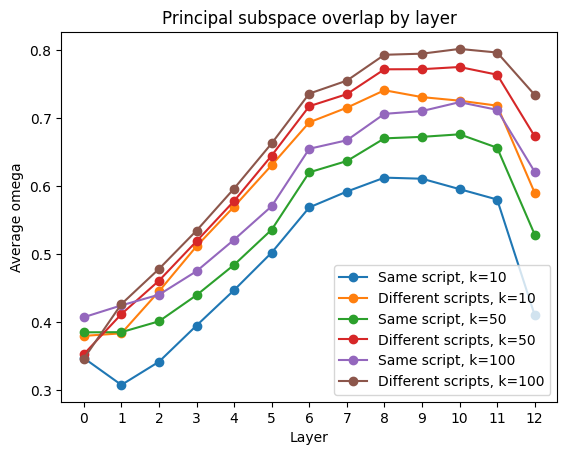

In [32]:
for k in [10, 50, 100]:
    for script_group in ["Same script", "Different scripts"]:
        values = average_overlap[
            (average_overlap["k"] == k) &
            (average_overlap["script_group"] == script_group)
        ]

        plt.plot(
            values["layer"],
            values["omega"],
            marker="o",
            label=f"{script_group}, k={k}"
        )

plt.xlabel("Layer")
plt.ylabel("Average omega")
plt.title("Principal subspace overlap by layer")
plt.xticks(range(13))
plt.legend()
plt.show()

In [33]:
selected_layer = 8
selected_k = 50
selected_results = overlap_results[
    (overlap_results["layer"] == selected_layer) &
    (overlap_results["k"] == selected_k)
]

overlap_matrix = selected_results.pivot(
    index="source_language",
    columns="target_language",
    values="omega"
)

# Keep languages in the same order
overlap_matrix = overlap_matrix.reindex(index=LANGS, columns=LANGS)

overlap_matrix

target_language,eng_Latn,fra_Latn,deu_Latn,rus_Cyrl,cmn_Hans,yor_Latn
source_language,,,,,,
eng_Latn,NaN,0.915982,0.913402,0.890030,0.839716,0.348120
fra_Latn,0.922820,NaN,0.918785,0.911999,0.828778,0.389380
deu_Latn,0.911498,0.910391,NaN,0.918800,0.830017,0.378554
rus_Cyrl,0.893117,0.907180,0.922084,NaN,0.848473,0.395277
cmn_Hans,0.857811,0.836654,0.842953,0.857028,NaN,0.364954
yor_Latn,0.464751,0.486870,0.483123,0.490906,0.458444,NaN


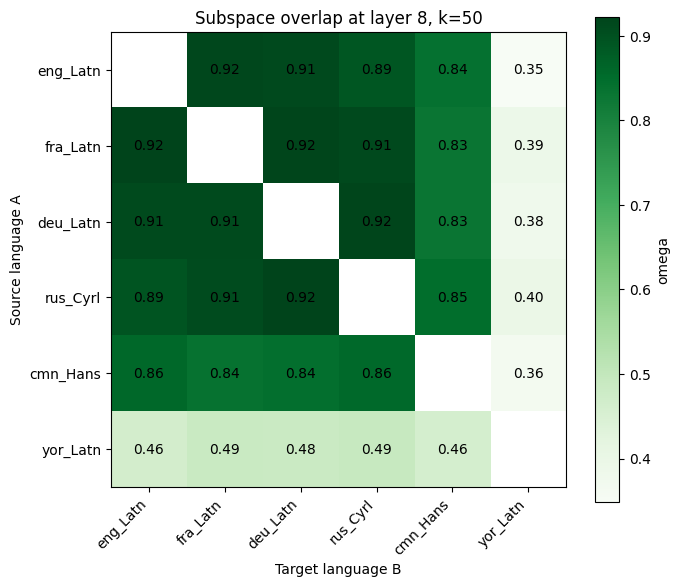

In [34]:
fig, ax = plt.subplots(figsize=(7, 6))

image = ax.imshow(overlap_matrix.values, cmap="Greens")

ax.set_xticks(range(len(LANGS)))
ax.set_yticks(range(len(LANGS)))
ax.set_xticklabels(LANGS, rotation=45, ha="right")
ax.set_yticklabels(LANGS)

for i in range(len(LANGS)):
    for j in range(len(LANGS)):
        value = overlap_matrix.iloc[i, j]
        if not np.isnan(value):
            ax.text(j, i, f"{value:.2f}", ha="center", va="center", color="black")

ax.set_xlabel("Target language B")
ax.set_ylabel("Source language A")
ax.set_title(f"Subspace overlap at layer {selected_layer}, k={selected_k}")

plt.colorbar(image, label="omega")
plt.tight_layout()
plt.show()

In [35]:
#41

In [36]:
language = "eng_Latn"
layer = 8
number_of_trials = 500

language_mean = representations_dev[language][layer].mean(axis=0)
centred_representations = representations_devtest[language][layer] - language_mean
representation_dimension = centred_representations.shape[1]

for k in [10, 50, 100]:
    captured_variances = []

    # Generate 500 random subspaces and compute c(X, U_rand)
    for trial in range(number_of_trials):
        random_subspace = create_random_subspace(
            representation_dimension,
            k,
            seed=trial
        )

        captured_variances.append(
            compute_captured_variance(
                centred_representations,
                random_subspace
            )
        )

    numerical_value = np.mean(captured_variances)
    theoretical_value = k / representation_dimension

    print(f"k={k}: numerical={numerical_value}, "
          f"theoretical={theoretical_value}")

k=10: numerical=0.013050652852935333, theoretical=0.013020833333333334
k=50: numerical=0.06511098058721822, theoretical=0.06510416666666667
k=100: numerical=0.13027926176013357, theoretical=0.13020833333333334


In [38]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

In [40]:
#48
source_language = "eng_Latn"
selected_layers = [0, 8, 12]

y_train = dev[source_language]["domain"].to_numpy()
y_test = devtest[source_language]["domain"].to_numpy()

# Majority-class baseline
majority_class = pd.Series(y_train).value_counts().idxmax()
majority_baseline = np.mean(y_test == majority_class)

results = []

for layer in selected_layers:
    X_train = representations_dev[source_language][layer]

    classifier = LogisticRegression(max_iter=2000)
    classifier.fit(X_train, y_train)

    for target_language in LANGS:
        X_test = representations_devtest[target_language][layer]
        accuracy = classifier.score(X_test, y_test)

        results.append([
            layer,
            source_language,
            target_language,
            accuracy
        ])

results = pd.DataFrame(
    results,
    columns=["layer", "source", "target", "accuracy"]
)

print(f"Majority class: {majority_class}")
print(f"Majority-class baseline: {majority_baseline:.3f}")

results

Majority class: wikinews
Majority-class baseline: 0.337


,layer,source,target,accuracy
0,0,eng_Latn,eng_Latn,0.712451
1,0,eng_Latn,fra_Latn,0.504941
2,0,eng_Latn,deu_Latn,0.589921
3,0,eng_Latn,rus_Cyrl,0.489130
4,0,eng_Latn,cmn_Hans,0.547431
5,0,eng_Latn,yor_Latn,0.397233
6,8,eng_Latn,eng_Latn,0.779644
7,8,eng_Latn,fra_Latn,0.750000
8,8,eng_Latn,deu_Latn,0.713439
9,8,eng_Latn,rus_Cyrl,0.682806


In [41]:
#49
source_language = "eng_Latn"
selected_layers = [0, 8, 12]

y_train = dev[source_language]["domain"].to_numpy()
y_test = devtest[source_language]["domain"].to_numpy()

centred_results = []

for layer in selected_layers:
    # Centre English training representations using English dev mean
    source_mean = representations_dev[source_language][layer].mean(axis=0)
    X_train = representations_dev[source_language][layer] - source_mean

    classifier = LogisticRegression(max_iter=2000)
    classifier.fit(X_train, y_train)

    for target_language in LANGS:
        # Centre each target language using its own dev mean
        target_mean = representations_dev[target_language][layer].mean(axis=0)
        X_test = representations_devtest[target_language][layer] - target_mean

        accuracy = classifier.score(X_test, y_test)

        centred_results.append([
            layer,
            source_language,
            target_language,
            accuracy
        ])

centred_results = pd.DataFrame(
    centred_results,
    columns=["layer", "source", "target", "accuracy"]
)

centred_results

,layer,source,target,accuracy
0,0,eng_Latn,eng_Latn,0.712451
1,0,eng_Latn,fra_Latn,0.593874
2,0,eng_Latn,deu_Latn,0.586957
3,0,eng_Latn,rus_Cyrl,0.558300
4,0,eng_Latn,cmn_Hans,0.581028
5,0,eng_Latn,yor_Latn,0.394269
6,8,eng_Latn,eng_Latn,0.780632
7,8,eng_Latn,fra_Latn,0.748024
8,8,eng_Latn,deu_Latn,0.733202
9,8,eng_Latn,rus_Cyrl,0.725296
